# clock/13 — what drives the *middle* (implementing a specific intent)?

The LM is mid-implementation: the **current** condition is prefilled up to `    {var} =`, and it is
about to write the RHS that implements it. We **ablate** a set of attention heads *during* that
implementation — not by diverting them to a target span (as in `09`), but by **restricting them to an
attention sink** (the first `<|im_start|>` token, position 0): those heads can only stare at a
meaningless token while the RHS is generated. Then we watch the downstream effect on the generated
implementation.

Same prompt machinery as `09 §5`; the only change is `keep_positions = [SINK_POS]` instead of the
target span. Barebones qualitative check for **goal | gaze | decision** heads (+ a count-matched
**random** control). Scale-up mirrors `09 §8–9` once the qualitative effect looks real.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, random, logging, json
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "7")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
from collections import defaultdict, Counter
from rich.console import Console
from rich.theme import Theme
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}")

2026-07-24 15:35:57 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-07-24 15:35:57 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-24 15:35:57 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-07-24 15:35:57 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-24 15:35:57 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-07-24 15:35:57 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-07-24 15:36:20 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-07-24 15:36:20 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-07-24 15:36:20 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40


## 1. Head sets — goal | gaze | decision (+ random control)

goal = trained mask @0.9 (32B band 25–55); gaze = top-K step-lookback (equal-N to goal by default);
decision = completion mask (lam10.0 @0.8). `random_like` matches a set's per-layer head count.

In [3]:
from src.goals.head_loc_attn import HeadMask
from scripts.clock.score_condition_heads import load_head_scores
from src.goals.oid_gaze import cache_root

VERSION = "conditions"

# -- goal heads (trained mask @0.9, 32B band 25-55) --
GOAL_THRESHOLD, GOAL_BAND = 0.9, (25, 56)
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]

# -- gaze heads (top-K step-lookback; equal-N to goal) --
GAZE_TOPK = len(goal_heads)
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=15, compare_with="mean")["combined"]
_flat = np.argsort(gaze_scores, axis=None)[::-1][:GAZE_TOPK]
gaze_heads = [(int(i // N_HEADS), int(i % N_HEADS)) for i in _flat]

# -- decision heads (completion mask, tag lam10.0 @0.8) --
DEC_TAG, DEC_THRESHOLD = "lam10.0", 0.8
_root = os.path.join(cache_root(MODEL_NAME, VERSION), "completion_mask")
_cand = [t for t in os.listdir(_root) if os.path.isdir(os.path.join(_root, t)) and DEC_TAG in t]
assert _cand, f"no completion_mask with tag {DEC_TAG!r} under {_root}"
_latest = max(_cand, key=lambda t: os.path.getmtime(os.path.join(_root, t)))
dck = torch.load(os.path.join(_root, _latest, "mask.pt"), map_location="cpu", weights_only=False)
dec_layers = [int(x) for x in dck["layers"]]
dmv = dck["mask_values"].numpy()
decision_heads = [(dec_layers[li], int(h)) for li, h in np.argwhere(dmv > DEC_THRESHOLD)]

def random_like(reference_heads, rng):
    per_layer = Counter(l for l, _ in reference_heads)
    out = []
    for l, cnt in per_layer.items():
        out += [(l, h) for h in rng.sample(range(N_HEADS), min(cnt, N_HEADS))]
    return out

HEAD_SETS = {"goal": goal_heads, "gaze": gaze_heads, "decision": decision_heads}
for name, hs in HEAD_SETS.items():
    ls = sorted({l for l, _ in hs})
    print(f"{name:9s}: {len(hs):4d} heads · layers {min(ls)}-{max(ls)}")

goal     :  122 heads · layers 28-55
gaze     :  122 heads · layers 8-61
decision :  181 heads · layers 11-62


## 2. Dissociation prompt (mid-implementation) + the sink

`build_dissociation_prompt` (from `09 §1`): priors complete + single-line; the **current** slot
prefilled up to `    {var} =`, cut at the pivot. `SINK_POS = 0` is the first prompt token
(`<|im_start|>`) — the meaningless attention sink the ablated heads are restricted to.

In [4]:
from src.goals.multiline_prompts import build_example

PIVOT_TRAILING_SPACE = False   # cut at `= ` so the RHS starts clean (matches 09's trailsp variant)
SINK_POS = 0                  # first token of the prompt = the attention sink

def build_dissociation_prompt(mt, rng, current_slot, n_conditions,
                              naming="letters", lang="python", trailing_space=None, **kw):
    ts = PIVOT_TRAILING_SPACE if trailing_space is None else trailing_space
    ex = build_example(mt=mt, rng=rng, target_slot=current_slot, n_conditions=n_conditions,
                       mode="chat", style="singleline", naming=naming, lang=lang,
                       prior_style="singleline", **kw)
    tvar = ex["target_var"]; fp = ex["full_prompt"]
    line_start = fp.rfind(f"\n    {tvar} =") + 1
    assign_eq  = fp.index("=", line_start)
    cut = assign_eq + 2 if ts else assign_eq + 1
    ex["dissoc_prompt"] = fp[:cut]; ex["current_slot"] = current_slot; ex["trailing_space"] = ts
    ids = mt.tokenizer(ex["dissoc_prompt"], add_special_tokens=False)["input_ids"]
    ex["prompt_ids"] = ids; ex["pivot_pos"] = len(ids) - 1
    return ex

# demo
_ex = build_dissociation_prompt(mt, random.Random(7), current_slot=2, n_conditions=5)
print(f"CURRENT slot={_ex['current_slot']} (var {_ex['target_var']}, {_ex['target_pred']})  "
      f"K={_ex['n_conditions']}  pivot_pos={_ex['pivot_pos']}")
for i, t in enumerate(_ex["spec"].spec_texts):
    print(f"   [{i}] {_ex['var_names'][i]}: {t}{'  <== CURRENT' if i==_ex['current_slot'] else ''}")
print("   last tokens:", [mt.tokenizer.decode([t]) for t in _ex["prompt_ids"][-5:]])
print("   SINK token :", repr(mt.tokenizer.decode([_ex['prompt_ids'][SINK_POS]])))

CURRENT slot=2 (var c, digit_sum_gt)  K=5  pivot_pos=288
   [0] a: n is a power of two
   [1] b: n is a perfect cube
   [2] c: the sum of n's digits is greater than 5  <== CURRENT
   [3] d: n is odd
   [4] e: all of n's digits are even
   last tokens: ['(n', ')\n', '   ', ' c', ' =']
   SINK token : '<|im_start|>'


## 3. Core intervention — restrict selected heads to the sink

Copied from `09 §5`. `forward_restrict_to_span` (single next-token) and
`generate_restricted_to_span` (greedy, non-cached so the restriction holds for the pivot **and every
generated RHS token**). We pass `keep_positions=[SINK_POS]` to ablate; `selected_heads=[]` = baseline.

In [5]:
from src.functional import get_module_nnsight

@torch.no_grad()
def forward_restrict_to_span(mt, inputs, selected_heads, keep_positions, q_positions):
    """Forward pass where each (layer, head) in `selected_heads` may attend, from each query in
    `q_positions`, ONLY to `keep_positions` (all other keys -> -inf pre-softmax)."""
    seq_len = inputs["input_ids"].shape[1]
    device  = next(mt._model.parameters()).device
    keep = torch.tensor(sorted(set(keep_positions)), device=device, dtype=torch.long)
    qpos = torch.tensor(sorted(set(q_positions)),   device=device, dtype=torch.long)
    by_layer = {}
    for (l, h) in selected_heads:
        m = by_layer.get(l)
        if m is None:
            m = torch.zeros(1, N_HEADS, seq_len, seq_len, device=device); by_layer[l] = m
        m[0, h, qpos.unsqueeze(1), :] = -torch.inf
        m[0, h, qpos.unsqueeze(1), keep.unsqueeze(0)] = 0.0
    with mt.trace(inputs, scan=False, validate=False):
        for l in by_layer:
            sm = get_module_nnsight(mt, mt.attn_module_name_format.format(l)) \
                    .source.attention_interface_0.source.nn_functional_softmax_0
            sm.input = sm.input + by_layer[l].to(sm.input.device)
        logits = mt.output.logits.save()
    return logits.float()

@torch.no_grad()
def generate_restricted_to_span(mt, prompt_ids, selected_heads, keep_positions, q_start,
                                max_new=30, stop_suffix=None, return_step_logits=False):
    """Greedy NON-CACHED decode; restriction re-applied to all query rows >= q_start of every
    `selected_heads` each step (they may attend ONLY to keep_positions). selected_heads=[] -> baseline."""
    if stop_suffix is None:
        stop_suffix = [mt.tokenizer.eos_token, "\n", "\n\n"]
    stop_suffix = [s for s in stop_suffix if s]
    device = next(mt._model.parameters()).device
    ids = torch.tensor([list(prompt_ids)], device=device)
    l2h = defaultdict(list)
    for l, h in sorted(selected_heads): l2h[l].append(h)
    keep_set = set(int(k) for k in keep_positions)
    gen, step_logits = [], []
    for _ in range(max_new):
        seq = ids.shape[1]
        kvec = torch.zeros(seq, device=device)
        if selected_heads:
            out_keys = [k for k in range(seq) if k not in keep_set]
            if out_keys: kvec[torch.tensor(out_keys, device=device)] = float("-inf")
        with mt.trace({"input_ids": ids, "attention_mask": torch.ones_like(ids)},
                      scan=False, validate=False):
            for L in sorted(l2h):
                sm = get_module_nnsight(mt, mt.attn_module_name_format.format(L)) \
                        .source.attention_interface_0.source.nn_functional_softmax_0
                km = torch.zeros(1, N_HEADS, seq, seq, device=device)
                for h in l2h[L]: km[0, h, q_start:, :] += kvec
                sm.input = sm.input + km.to(sm.input.device, sm.input.dtype)
            logits = mt.output.logits[:, -1, :].save()
        step_logits.append(logits[0].float().detach().cpu())
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id: break
        tok_str = mt.tokenizer.decode([nxt]); gen.append(nxt)
        if any(tok_str.endswith(s) for s in stop_suffix): break
        ids = torch.cat([ids, torch.tensor([[nxt]], device=device)], dim=1)
    text = mt.tokenizer.decode(gen, skip_special_tokens=True)
    return (text, step_logits) if return_step_logits else text

In [6]:
@torch.no_grad()
def generate_restricted_to_span_cached(mt, prompt_ids, selected_heads, keep_positions, q_start,
                                       max_new=30, stop_suffix=None, return_step_logits=False):
    """KV-CACHE-aware twin of generate_restricted_to_span. The sink restriction is applied to every
    query whose ABSOLUTE position >= q_start — the pivot during prefill, then the single current
    query at each decode step — and past_key_values is carried forward (so each restricted token's
    modified K/V are cached and seen by later tokens). Greedy => deterministic => must match the
    non-cached recompute. O(seq) per step instead of O(seq^2)."""
    if stop_suffix is None:
        stop_suffix = [mt.tokenizer.eos_token, "\n", "\n\n"]
    stop_suffix = [s for s in stop_suffix if s]
    device = next(mt._model.parameters()).device
    l2h = defaultdict(list)
    for l, h in sorted(selected_heads): l2h[l].append(h)
    keep_set = set(int(k) for k in keep_positions)

    ids_full = torch.tensor([list(prompt_ids)], device=device)
    P = ids_full.shape[1]
    attn = torch.ones_like(ids_full)
    past = None
    gen, step_logits = [], []

    def _kvec(kv_len):
        v = torch.zeros(kv_len, device=device)
        out = [k for k in range(kv_len) if k not in keep_set]
        if out: v[torch.tensor(out, device=device)] = float("-inf")
        return v

    for step in range(max_new):
        kv_len = ids_full.shape[1]                          # keys = full seq so far (cache + current)
        if step == 0:
            cur_ids, q_len, q_offset = ids_full, kv_len, 0  # prefill: q rows are absolute 0..P-1
        else:
            cur_ids, q_len, q_offset = ids_full[:, -1:], 1, kv_len - 1   # decode: single new query
        inp = {"input_ids": cur_ids, "attention_mask": attn,
               "past_key_values": past, "use_cache": True}
        kvec = _kvec(kv_len) if selected_heads else None
        with mt.trace(inp, scan=False, validate=False):
            if selected_heads:
                for L in sorted(l2h):
                    sm = get_module_nnsight(mt, mt.attn_module_name_format.format(L)) \
                            .source.attention_interface_0.source.nn_functional_softmax_0
                    km = torch.zeros(1, N_HEADS, q_len, kv_len, device=device)
                    for qi in range(q_len):
                        if q_offset + qi >= q_start:                  # only restrict rows >= q_start
                            for h in l2h[L]: km[0, h, qi, :] += kvec
                    sm.input = sm.input + km.to(sm.input.device, sm.input.dtype)
            logits = mt.output.logits[:, -1, :].save()
            past = mt.output.past_key_values.save()
        step_logits.append(logits[0].float().detach().cpu())
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id: break
        tok_str = mt.tokenizer.decode([nxt]); gen.append(nxt)
        if any(tok_str.endswith(s) for s in stop_suffix): break
        ids_full = torch.cat([ids_full, torch.tensor([[nxt]], device=device)], dim=1)
        attn = torch.ones_like(ids_full)
    text = mt.tokenizer.decode(gen, skip_special_tokens=True)
    return (text, step_logits) if return_step_logits else text

### 3b. Equivalence check — cached vs non-cached

Assert the two generators agree: **behaviorally** (identical decoded text + identical per-position
argmax) and **quantitatively** (max |Δlogit| across the first few positions). bf16 makes bit-exact
logits impossible, so argmax/text are the hard guarantees and the logit drift is reported. The
`none` arm checks the cache plumbing itself (no intervention); `goal`/`decision` check it with the
softmax restriction active.

In [7]:
import itertools
from rich.markup import escape

CHECK_SEEDS = [7, 21]
CHECK_ARMS  = {"none": [], "goal": goal_heads, "decision": decision_heads}
N_POS       = 4          # compare logits across the first N generated positions
LOGIT_ATOL  = 5e-1       # bf16 drift tolerance for the SOFT logit check; argmax must match exactly
CURRENT_SLOT = 2        # which of the K conditions is the "current" one (pivot for dissociation)
N_COND      = 5          # number of conditions in the dissociation prompt

all_ok = True
for seed, (aname, hs) in itertools.product(CHECK_SEEDS, CHECK_ARMS.items()):
    ex = build_dissociation_prompt(mt, random.Random(seed), current_slot=CURRENT_SLOT, n_conditions=N_COND)
    pid, q0 = ex["prompt_ids"], ex["pivot_pos"]
    tn, ln = generate_restricted_to_span(mt, pid, hs, [SINK_POS], q0, max_new=N_POS, return_step_logits=True)
    tc, lc = generate_restricted_to_span_cached(mt, pid, hs, [SINK_POS], q0, max_new=N_POS, return_step_logits=True)
    n = min(len(ln), len(lc))
    diffs = [float((ln[i] - lc[i]).abs().max()) for i in range(n)]
    arg_ok  = all(int(ln[i].argmax()) == int(lc[i].argmax()) for i in range(n))
    text_ok = (tn == tc)
    len_ok  = (len(ln) == len(lc))
    ok = arg_ok and text_ok and len_ok
    all_ok &= ok
    color = "green" if ok else "red"
    per_pos = " ".join(f"{d:.2e}" for d in diffs)
    rich_print(f"[{color}]{'OK  ' if ok else 'FAIL'}[/{color}] seed={seed} {aname:9s}  "
               f"argmax={'match' if arg_ok else 'DIFF'}  text={'match' if text_ok else 'DIFF'}  "
               f"len={len(ln)}/{len(lc)}  max|dlogit|={max(diffs) if diffs else 0:.3e}  per-pos={per_pos}")
    if not text_ok:
        rich_print(f"     non-cached={escape(repr(tn))}")
        rich_print(f"     cached    ={escape(repr(tc))}")
    if diffs and max(diffs) >= LOGIT_ATOL:
        rich_print(f"     [yellow]note: max|dlogit|={max(diffs):.3e} >= {LOGIT_ATOL} — bf16 drift, or a bug if argmax/text also differ[/yellow]")

assert all_ok, "cached vs non-cached MISMATCH (see rows above)"
rich_print("[bold green]all equivalence checks passed[/bold green] (identical text + per-position argmax)")

OK   seed=7 none       argmax=match  text=match  len=4/4  max|dlogit|=2.500e-01  per-pos=0.00e+00 2.50e-01 1.56e-01
1.56e-01

OK   seed=7 goal       argmax=match  text=match  len=4/4  max|dlogit|=2.500e-01  per-pos=0.00e+00 2.50e-01 2.50e-01
2.50e-01

OK   seed=7 decision   argmax=match  text=match  len=4/4  max|dlogit|=1.562e-01  per-pos=0.00e+00 1.56e-01 1.56e-01
1.25e-01

OK   seed=21 none       argmax=match  text=match  len=4/4  max|dlogit|=2.188e-01  per-pos=0.00e+00 1.33e-01 
1.56e-01 2.19e-01

OK   seed=21 goal       argmax=match  text=match  len=4/4  max|dlogit|=2.500e-01  per-pos=0.00e+00 1.56e-01 
2.50e-01 1.88e-01

OK   seed=21 decision   argmax=match  text=match  len=4/4  max|dlogit|=2.500e-01  per-pos=0.00e+00 2.50e-01 
2.50e-01 2.19e-01

all equivalence checks passed (identical text + per-position argmax)

## 4. Qualitative check — does sinking each head set break the implementation?

For a few seeds: the **baseline** RHS (no restriction), then the RHS with each head set restricted to
the sink, and a **random**-matched control. Eyeball whether ablating goal / gaze / decision heads
degrades the current-condition implementation more than random.

In [8]:
def isolate_current_span(text, ex, current):
    """Trim a full greedy generation (RHS onward, generated until EOS/max_new) down to just the
    CURRENT condition's code. `text` begins right after `    {cur_var} =`. Rule-based cut at the START
    of the NEXT variable's assignment line (`{next_var} =`); if CURRENT is the last condition, cut at
    the terminal statement (`return` / `print`). Falls back to the whole text if no marker is found."""
    K = ex["n_conditions"]
    if current + 1 < K:
        nxt = ex["var_names"][current + 1]
        m = re.search(rf"\n\s*{re.escape(nxt)}\s*=(?!=)", text)   # e.g. next var `d =` at line start
    else:
        m = re.search(r"\n\s*(return|print)", text)               # last cond -> terminal statement
    return (text[:m.start()] if m else text).strip()

In [9]:
from rich.markup import escape
from src.goals.goalscope import apply_goalscope
from src.tokens import TokenizerOutput

SEEDS = [3, 6, 12, 24, 48, 96]
CURRENT_SLOT, N_COND, MAX_NEW = 2, 5, 64
N_RAND_HEADS = 150
# GoalScope readout config for the pivot diagnostic (tune freely; same knobs as notebook 12)
GS_READOUT = dict(strategy="additive", alpha=0.2, steer_layer_range=(35, 46), max_new_tokens=64)

# one fixed random control set (same heads across all seeds), sampled across all layers x heads
_rng = random.Random(0)
rand_heads = _rng.sample([(l, h) for l in range(N_LAYER) for h in range(N_HEADS)], N_RAND_HEADS)

ARMS = {"goal": ("salmon1", goal_heads), "gaze": ("plum1", gaze_heads),
        "decision": ("bright_cyan", decision_heads), f"random({N_RAND_HEADS})": ("deep_pink1", rand_heads)}

def goalscope_at_pivot(prompt_ids, q0, hs):
    """apply_goalscope at the pivot q0 (where ablation starts), reusing the SAME tokenization as the
    ablation (ex["prompt_ids"]) so the position aligns exactly and the prompt isn't re-tokenized."""
    dev = next(mt._model.parameters()).device
    gs_inputs = TokenizerOutput(data=dict(
        input_ids=torch.tensor([list(prompt_ids)], device=dev),
        attention_mask=torch.ones(1, len(prompt_ids), dtype=torch.long, device=dev)))
    res = apply_goalscope(gs_inputs, mt=mt, selected_heads=sorted(hs), token_positions=[q0],
                          show=False, include_noncode=False, **GS_READOUT)
    return (res[0]["patched_gen"] if res else "").replace(chr(10), " ")

for seed in SEEDS:
    ex = build_dissociation_prompt(mt, random.Random(seed), current_slot=CURRENT_SLOT, n_conditions=N_COND)
    pid, q0, var = ex["prompt_ids"], ex["pivot_pos"] - 1, ex["target_var"]
    print(f"prompt='''{mt.tokenizer.decode(pid)}'''")
    cur_txt = ex["spec"].spec_texts[ex["current_slot"]]
    act_tok = mt.tokenizer.decode([pid[q0]])                     # token at q0 = start of ablation
    _EOS = [mt.tokenizer.eos_token]
    base = isolate_current_span(
        generate_restricted_to_span(mt, pid, [], [SINK_POS], q0, max_new=MAX_NEW, stop_suffix=None),
        ex, ex["current_slot"])
    lines = [f"[bold]seed={seed}[/bold]  CURRENT (var {var}): [cyan]{escape(cur_txt)}[/cyan]"
             f"   [grey58]actuation token @q0={escape(repr(act_tok))}[/grey58]",
             f"[sea_green3]  baseline              {var} = {escape(repr(base))}[/sea_green3]"]
    for name, (color, hs) in ARMS.items():
        gen = isolate_current_span(
            generate_restricted_to_span(mt, pid, hs, [SINK_POS], q0, max_new=MAX_NEW, stop_suffix=None),
            ex, ex["current_slot"])
        readout = goalscope_at_pivot(pid, q0, hs)
        lines.append(f"[{color}]  sink {name:16s} {var} = {escape(repr(gen))}[/{color}]")
        lines.append(f"[{color}]       \u2514 goalscope@q0: {escape(readout)}[/{color}]")
    rich_print("\n".join(lines))

prompt='''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is smaller than the number obtained by reversing its digits
2. the sum of n's proper divisors is greater than n
3. n is a perfect cube
4. n is coprime with 15
5. the product of n's digits is greater than 0

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each con

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

... (27 outputs left out)

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

GoalScope[additive]:   0%|          | 0/1 [00:00<?, ?it/s]

seed=96  CURRENT (var c): the sum of n's digits is greater than 5   actuation token @q0=' c'
  baseline              c = 'sum(int(digit) for digit in str(n)) > 5'
  sink goal             c = 'sum(int(digit) for digit in str(n)) > 5'
       └ goalscope@q0: Sure, but I need to know the specific line number and the context of the code. Here's a 
quick breakdown:  1. Sum of digits: `sum(int(digit) for digit in str(number)) > 9` 2. Greater than nine: `number > 
9` 3. Check if the sum
  sink gaze             c = 'sum(int(digit) for digit in str(n)) > 9'
       └ goalscope@q0: I'm analyzing the code to determine if the sum of the digits of a number is greater than the
number itself.
  sink decision         c = 'sum(int(digit) for digit in str(n)) > 5'
       └ goalscope@q0: I'm checking if the condition is true.
  sink random(150)      c = 'sum(int(digit) for digit in str(n)) > 5'
       └ goalscope@q0: I'm analyzing the specific line of code you're referring to.

## 5. The opposite — blind everyone *else* to the current condition's span

§5's sink-restriction destroyed the model (forcing ~1000 heads onto one token). Gentler isolation:
leave the complement heads (all except the selected set, layers `>= FROM_LAYER_IDX`) **fully
functional**, but **blind them to the current condition's span** — `-inf` on only those key columns,
everything else visible. So only the **selected set** (+ untouched early layers) can read *what is
being implemented*. If the RHS still comes out right, the selected heads suffice to route the current
condition to the pivot.

In [10]:
from rich.markup import escape
from src.tokens import find_token_range

FROM_LAYER_IDX = 20  # only blind layers >= this
BLOCK_WHICH = (
    "full"  # "full" = whole spec-text span | "id" = discriminative id-substr tokens
)


def locate_condition_spans(mt, ex):
    """Per condition -> token span of its spec text in the dissoc_prompt (add_special_tokens=False,
    the SAME tokenization as ex['prompt_ids'] / q0). Copied from 09 §2."""
    prompt = ex["dissoc_prompt"]
    offsets = [
        tuple(p)
        for p in mt.tokenizer(
            prompt, return_offsets_mapping=True, add_special_tokens=False
        )["offset_mapping"]
    ]
    spec = ex["spec"]
    out = []
    for k, (text, subs) in enumerate(zip(spec.spec_texts, spec.id_substrs)):
        base = prompt.find(text)
        full = None
        sub_ranges = []
        if base != -1:
            try:
                full = list(
                    find_token_range(prompt, text, offset_mapping=offsets, occurrence=0)
                )
            except (ValueError, AssertionError):
                full = None
            for ss in subs:
                rel = text.find(ss)
                if rel == -1:
                    continue
                occ = prompt.count(ss, 0, base + rel)
                try:
                    ts, te = find_token_range(
                        prompt, ss, offset_mapping=offsets, occurrence=occ
                    )
                    sub_ranges.append([ts, te])
                except (ValueError, AssertionError):
                    continue
        out.append(
            {
                "cond": k,
                "var": ex["var_names"][k],
                "text": text,
                "full_span": full,
                "id_substr_spans": sub_ranges,
            }
        )
    return out


def condition_block_positions(spans, slot, which="full"):
    s = spans[slot]
    if which == "id":
        return sorted({p for r in s["id_substr_spans"] for p in range(r[0], r[1])})
    return list(range(*s["full_span"])) if s["full_span"] else []


@torch.no_grad()
def generate_blocking_span(
    mt, prompt_ids, block_heads, block_positions, q_start, max_new=64, stop_suffix=None
):
    """Greedy NON-CACHED decode; each (l,h) in `block_heads` is BLINDED to `block_positions` (those
    keys -> -inf from query rows >= q_start) but sees everything else normally. Gentle: heads keep
    all other keys, unlike the sink restriction. block_heads=[] -> baseline (nobody blinded)."""
    if stop_suffix is None:
        stop_suffix = [mt.tokenizer.eos_token, "\n", "\n\n"]
    stop_suffix = [s for s in stop_suffix if s]
    device = next(mt._model.parameters()).device
    ids = torch.tensor([list(prompt_ids)], device=device)
    l2h = defaultdict(list)
    for l, h in sorted(block_heads):
        l2h[l].append(h)
    block = torch.tensor(
        sorted(set(int(p) for p in block_positions)), device=device, dtype=torch.long
    )
    gen = []
    for _ in range(max_new):
        seq = ids.shape[1]
        with mt.trace(
            {"input_ids": ids, "attention_mask": torch.ones_like(ids)},
            scan=False,
            validate=False,
        ):
            if block_heads and len(block):
                for L in sorted(l2h):
                    sm = get_module_nnsight(
                        mt, mt.attn_module_name_format.format(L)
                    ).source.attention_interface_0.source.nn_functional_softmax_0
                    km = torch.zeros(1, N_HEADS, seq, seq, device=device)
                    for h in l2h[L]:
                        km[0, h, q_start:, block] = float(
                            "-inf"
                        )  # blind to the condition span only
                    sm.input = sm.input + km.to(sm.input.device, sm.input.dtype)
            logits = mt.output.logits[:, -1, :].save()
        nxt = int(logits[0].argmax(-1))
        if nxt == mt.tokenizer.eos_token_id:
            break
        tok_str = mt.tokenizer.decode([nxt])
        gen.append(nxt)
        if any(tok_str.endswith(s) for s in stop_suffix):
            break
        ids = torch.cat([ids, torch.tensor([[nxt]], device=device)], dim=1)
    return mt.tokenizer.decode(gen, skip_special_tokens=True)


def complement_heads(selected, from_layer):
    """All (layer, head) in layers [from_layer, N_LAYER) EXCEPT the selected set — the heads to blind."""
    sel = set(map(tuple, selected))
    return [
        (l, h)
        for l in range(from_layer, N_LAYER)
        for h in range(N_HEADS)
        if (l, h) not in sel
    ]


for seed in SEEDS:
    ex = build_dissociation_prompt(
        mt, random.Random(seed), current_slot=CURRENT_SLOT, n_conditions=N_COND
    )
    pid, q0, var = ex["prompt_ids"], ex["pivot_pos"], ex["target_var"]
    print(f"prompt='''{mt.tokenizer.decode(pid)}'''")
    cur_txt = ex["spec"].spec_texts[ex["current_slot"]]
    spans = locate_condition_spans(mt, ex)
    block_pos = condition_block_positions(spans, ex["current_slot"], BLOCK_WHICH)
    # block_pos = list(range(block_pos[0] - 50, block_pos[-1] + 50)) if block_pos else [] #! check with some buffer around the span
    block_pos = (
        list(range(block_pos[0] - 1, len(pid))) if block_pos else []
    )  #! block from a few tokens before the span to the end of the prompt
    # code_start = find_token_range(
    #     string=mt.tokenizer.decode(pid),
    #     substring="<code>\ndef check_conditions(n: int):",
    #     tokenizer=mt.tokenizer,
    # )[0]
    # block_pos = (
    #     list(range(block_pos[0] - 2, code_start+1)) if block_pos else []
    # )  #! block from a few tokens before the span to the start of the code block

    blocked_txt = (
        mt.tokenizer.decode([pid[p] for p in block_pos]) if block_pos else "(not found)"
    )
    _EOS = [mt.tokenizer.eos_token]
    base = isolate_current_span(
        generate_blocking_span(mt, pid, [], block_pos, q0, max_new=MAX_NEW, stop_suffix=None),
        ex, ex["current_slot"])
    lines = [
        f"[bold]seed={seed}[/bold]  CURRENT (var {var}): [cyan]{escape(cur_txt)}[/cyan]"
        f"   [grey58]blinding others (L>={FROM_LAYER_IDX}) to span={escape(repr(blocked_txt))}[/grey58]",
        f"   pivot token @q0={escape(repr(mt.tokenizer.decode([pid[q0]])))}",
        f"[sea_green3]  baseline (all see)        {var} = {escape(repr(base))}[/sea_green3]",
    ]
    if not block_pos:
        rich_print(
            "\n".join(lines)
            + "\n  [red](current condition span not located -> skipped)[/red]"
        )
        continue
    for name, (color, hs) in ARMS.items():
        comp = complement_heads(hs, FROM_LAYER_IDX)
        gen = isolate_current_span(
            generate_blocking_span(mt, pid, comp, block_pos, q0, max_new=MAX_NEW, stop_suffix=None),
            ex, ex["current_slot"])
        lines.append(
            f"[{color}]  only {name:15s} sees {var} = {escape(repr(gen))}[/{color}]"
            f"  [grey58]({len(comp)} heads blinded)[/grey58]"
        )
    rich_print("\n".join(lines))

prompt='''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is smaller than the number obtained by reversing its digits
2. the sum of n's proper divisors is greater than n
3. n is a perfect cube
4. n is coprime with 15
5. the product of n's digits is greater than 0

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each con

seed=3  CURRENT (var c): n is a perfect cube   blinding others (L>=20) to span=". n is a perfect cube\n4. n is 
coprime with 15\n5. the product of n's digits is greater than 0\n\nFor each condition, in the order listed, assign 
the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the 
first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print 
statement that, using those variables, reports whether each condition passed individually and whether all of them 
passed collectively.\nCompute each condition's boolean result inside `check_conditions` (one local variable per 
condition); do not define any helper functions.\nDo not include any comments in your 
code.<|im_end|>\n<|im_start|>assistant\n<code>\ndef check_conditions(n: int):\n    a = int(str(abs(n))[::-1]) > 
abs(n)\n    b = n > 0 and sum(d for d in range(1, abs(n)) if n % d == 0) > n\n    c ="
   pivot token @q0=' ='
  baseline (all see)        c = 'round(abs(n) ** (1/3)) ** 3 == abs(n)'
  only goal            sees c = 'round(n ** (1/3)) ** 3 == n'  (1638 heads blinded)
  only gaze            sees c = 'n is a perfect square'  (1644 heads blinded)
  only decision        sees c = 'sum(i for i in range(1, n) if n % i == 0) > n'  (1589 heads blinded)
  only random(150)     sees c = '1  # 1 is a proper divisor of any n > 1'  (1661 heads blinded)

prompt='''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is a prime number
2. n is divisible by 2
3. all of n's digits are even
4. n has at least 2 digits
5. n is even

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not de

seed=6  CURRENT (var c): all of n's digits are even   blinding others (L>=20) to span=". all of n's digits are 
even\n4. n has at least 2 digits\n5. n is even\n\nFor each condition, in the order listed, assign the boolean 
result of the check to its own local variable, using single lowercase letters in order — `a` for the first 
condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement 
that, using those variables, reports whether each condition passed individually and whether all of them passed 
collectively.\nCompute each condition's boolean result inside `check_conditions` (one local variable per 
condition); do not define any helper functions.\nDo not include any comments in your 
code.<|im_end|>\n<|im_start|>assistant\n<code>\ndef check_conditions(n: int):\n    a = n > 1 and all(n % d != 0 for
d in range(2, int(abs(n) ** 0.5) + 1))\n    b = n % 2 == 0\n    c ="
   pivot token @q0=' ='
  baseline (all see)        c = 'all(int(d) % 2 == 0 for d in str(n))'
  only goal            sees c = 'all(int(digit) % 2 == 0 for digit in str(n)) for n in range(2, int(n**0.5) + 1) if
n % i == 0)'  (1638 heads blinded)
  only gaze            sees c = 'n is a perfect square'  (1644 heads blinded)
  only decision        sees c = 'all(n % i != 0 for i in range(2, int(n**0.5) + 1)) if n > 1 else False'  (1589 
heads blinded)
  only random(150)     sees c = '2'  (1661 heads blinded)

prompt='''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. all of n's digits are even
2. n has at least 3 digits
3. n has more than 2 divisors
4. n is coprime with 12
5. n is divisible by 17

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per co

seed=12  CURRENT (var c): n has more than 2 divisors   blinding others (L>=20) to span=". n has more than 2 
divisors\n4. n is coprime with 12\n5. n is divisible by 17\n\nFor each condition, in the order listed, assign the 
boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first 
condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement 
that, using those variables, reports whether each condition passed individually and whether all of them passed 
collectively.\nCompute each condition's boolean result inside `check_conditions` (one local variable per 
condition); do not define any helper functions.\nDo not include any comments in your 
code.<|im_end|>\n<|im_start|>assistant\n<code>\ndef check_conditions(n: int):\n    a = all(int(c) % 2 == 0 for c in
str(abs(n)))\n    b = len(str(abs(n))) >= 3\n    c ="
   pivot token @q0=' ='
  baseline (all see)        c = 'len([d for d in range(1, n + 1) if n % d == 0]) > 2'
  only goal            sees c = 'len([i for i in range(2, n) if n % i == 0]) > 2'  (1638 heads blinded)
  only gaze            sees c = 'all(int(c) % 2 == 0 for c in str(n))  # Check if all digits are even'  (1644 heads
blinded)
  only decision        sees c = 'len(str(n)) >= 3'  (1589 heads blinded)
  only random(150)     sees c = '100 <= n <= 999'  (1661 heads blinded)

... (2 outputs left out)

prompt='''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. the sum of n's proper divisors is greater than n
2. n is a power of two
3. n is a perfect cube
4. n has more than 2 ones in its binary representation
5. the sum of n's digits is greater than 20

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boole

seed=48  CURRENT (var c): n is a perfect cube   blinding others (L>=20) to span=". n is a perfect cube\n4. n has 
more than 2 ones in its binary representation\n5. the sum of n's digits is greater than 20\n\nFor each condition, 
in the order listed, assign the boolean result of the check to its own local variable, using single lowercase 
letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been 
checked, use a SINGLE print statement that, using those variables, reports whether each condition passed 
individually and whether all of them passed collectively.\nCompute each condition's boolean result inside 
`check_conditions` (one local variable per condition); do not define any helper functions.\nDo not include any 
comments in your code.<|im_end|>\n<|im_start|>assistant\n<code>\ndef check_conditions(n: int):\n    a = n > 0 and 
sum(d for d in range(1, abs(n)) if n % d == 0) > n\n    b = n > 0 and (n & (n - 1)) == 0\n    c ="
   pivot token @q0=' ='
  baseline (all see)        c = 'round(n ** (1/3)) ** 3 == n'
  only goal            sees c = 'round(n ** (1/3)) ** 3 == n'  (1638 heads blinded)
  only gaze            sees c = 'n is a perfect square'  (1644 heads blinded)
  only decision        sees c = 'n > 0 and (n & (n - 1)) == 0'  (1589 heads blinded)
  only random(150)     sees c = '7'  (1661 heads blinded)

prompt='''<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is coprime with 12
2. n is a power of two
3. the sum of n's digits is greater than 5
4. n is a palindrome (its digits read the same forwards and backwards)
5. n is odd

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_

seed=96  CURRENT (var c): the sum of n's digits is greater than 5   blinding others (L>=20) to span=". the sum of 
n's digits is greater than 5\n4. n is a palindrome (its digits read the same forwards and backwards)\n5. n is 
odd\n\nFor each condition, in the order listed, assign the boolean result of the check to its own local variable, 
using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.\nCompute each condition's boolean result
inside `check_conditions` (one local variable per condition); do not define any helper functions.\nDo not include 
any comments in your code.<|im_end|>\n<|im_start|>assistant\n<code>\ndef check_conditions(n: int):\n    a = 
math.gcd(n, 12) == 1\n    b = n > 0 and (n & (n - 1)) == 0\n    c ="
   pivot token @q0=' ='
  baseline (all see)        c = 'sum(int(digit) for digit in str(n)) > 5'
  only goal            sees c = 'sum(int(digit) for digit in str(n)) > 9'  (1638 heads blinded)
  only gaze            sees c = '1'  (1644 heads blinded)
  only decision        sees c = '(n & (n - 1)) == 0 and n != 0'  (1589 heads blinded)
  only random(150)     sees c = '2 ** int(math.log2(n)) == n  # Check if n is a power of two'  (1661 heads blinded)

## 6. Scaled eval — soft + hard machinery (adapted from 09)

Both interventions ask the same question: **does the CURRENT condition survive?** (§4 ablates a head
set → expect goal heads to *break* current; §5 isolates a set → expect the sufficient set to *keep*
current). So we score, per intervention, a forward-primitive that we can teacher-force (soft) and
greedy-decode (hard):

* **soft** — teacher-force each of the K condition RHS's from the pivot, sum mean-token log-prob →
  `p_k`; report `p_current`, whether the argmax is CURRENT, and `Δp_current` vs a clean pass.
* **hard** — generate the RHS under the intervention, cut at the newline, ask the oracle *per
  condition* (k-way, no current/target notion) → `current ∈ YES-slots` = **survives**.

`forward_restrict_to_span` (sink, from §3) covers §4; `forward_blocking_span` (below) covers §5.

In [11]:
import hashlib
from src.goals.condition_data import INT_PREDICATES
from src.utils.oracle_llms import ask_claude

_PRED_BY_ID = {p.id: p for p in INT_PREDICATES}


# ── canonical RHS references (soft-eval candidates) — copied from 09 §3 ────────
def get_condition_references(mt, ex):
    """Per condition k -> {cond, var, pred, rhs, rhs_ids}. `rhs` keeps the space after `=` unless the
    pivot already consumed it (ex['trailing_space']), so prompt_ids + rhs_ids retokenizes cleanly."""
    ts = ex.get("trailing_space", PIVOT_TRAILING_SPACE)
    spec = ex["spec"]; out = []
    for k in range(ex["n_conditions"]):
        pid, prm, var = spec.predicate_ids[k], spec.predicate_params[k], ex["var_names"][k]
        pred = _PRED_BY_ID[pid]; has_sl = pred.has_singleline_for(ex["lang"])
        full_line = (pred.render_singleline(prm, var, lang=ex["lang"]) if has_sl
                     else " / ".join(pred.render_multiline(prm, var, lang=ex["lang"])))
        m = re.match(rf"^\s*{re.escape(var)}\s*=", full_line)
        rhs = full_line[m.end():] if m else full_line
        if ts and rhs.startswith(" "): rhs = rhs[1:]
        rhs_ids = mt.tokenizer(rhs, add_special_tokens=False)["input_ids"]
        out.append({"cond": k, "var": var, "pred": pid, "rhs": rhs, "rhs_ids": rhs_ids})
    return out


# ── §5's teacher-forceable twin of generate_blocking_span ─────────────────────
@torch.no_grad()
def forward_blocking_span(mt, inputs, block_heads, block_positions, q_positions):
    """Forward where each (l,h) in `block_heads` is BLINDED to `block_positions` (those keys -> -inf)
    for every query in `q_positions`; all other keys stay visible. The teacher-forcing analogue of
    generate_blocking_span, so soft + hard see the same intervention."""
    seq_len = inputs["input_ids"].shape[1]
    device  = next(mt._model.parameters()).device
    block = torch.tensor(sorted(set(int(p) for p in block_positions)), device=device, dtype=torch.long)
    qpos  = torch.tensor(sorted(set(int(p) for p in q_positions)),     device=device, dtype=torch.long)
    by_layer = {}
    for (l, h) in block_heads:
        m = by_layer.get(l)
        if m is None:
            m = torch.zeros(1, N_HEADS, seq_len, seq_len, device=device); by_layer[l] = m
        if len(block):
            m[0, h, qpos.unsqueeze(1), block.unsqueeze(0)] = -torch.inf
    with mt.trace(inputs, scan=False, validate=False):
        for l in by_layer:
            sm = get_module_nnsight(mt, mt.attn_module_name_format.format(l)) \
                    .source.attention_interface_0.source.nn_functional_softmax_0
            sm.input = sm.input + by_layer[l].to(sm.input.device)
        logits = mt.output.logits.save()
    return logits.float()


# ── soft: per-condition RHS log-likelihood under an arbitrary forward primitive ─
@torch.no_grad()
def score_condition_lls(mt, ex, refs, forward_fn=None, length_norm=True):
    """(K,) mean per-token log p of each condition's canonical RHS, teacher-forced from the pivot.
    `forward_fn(inp, qpos) -> logits(1,seq,vocab)` applies the intervention on the RHS query rows;
    None -> clean pass. length_norm divides by #rhs tokens so longer RHS isn't penalised."""
    device = next(mt._model.parameters()).device
    pivot = ex["pivot_pos"]; base_ids = list(ex["prompt_ids"]); lls = []
    for r in refs:
        rhs_ids = r["rhs_ids"]; ids = base_ids + rhs_ids
        inp = {"input_ids": torch.tensor([ids], device=device),
               "attention_mask": torch.ones(1, len(ids), device=device)}
        qpos = list(range(pivot, pivot + len(rhs_ids)))          # queries that emit the RHS
        if forward_fn is not None:
            logits = forward_fn(inp, qpos)
        else:
            with mt.trace(inp, scan=False, validate=False):
                logits = mt.output.logits.save()
            logits = logits.float()
        logp = torch.log_softmax(logits[0], dim=-1)
        tgt = torch.tensor(rhs_ids, device=logp.device)
        pos = torch.arange(pivot, pivot + len(rhs_ids), device=logp.device)
        s = logp[pos, tgt].sum()
        lls.append(float((s / len(rhs_ids) if length_norm else s).cpu()))
    return np.asarray(lls)


def soft_metrics_current(cond_lls, current, tau=1.0):
    """Closed-set p_k over the K conditions, framed around CURRENT (the intent under test)."""
    lls = np.asarray(cond_lls, dtype=np.float64)
    p = np.exp((lls - lls.max()) / tau); p = p / p.sum()
    order = np.argsort(-lls)
    rank_current = int(np.where(order == current)[0][0]) + 1
    return {"p": p, "p_current": float(p[current]), "argmax": int(order[0]),
            "rank_current": rank_current, "current_is_argmax": bool(order[0] == current)}


# ── hard eval: lenient SINGLE-condition oracle (does the stub genuinely attempt CURRENT?) ──
# Only the CURRENT condition is checked (no k-way). Philosophy ported from clock/12 §7: grade the
# SUBSTANCE, not keywords; a small correct fragment of the right idea is a SUCCESS. The stub is real
# post-intervention code, so bugs / incompleteness / cut-off don't count against it — only relevance.
HARD_SYS = """You are grading a short snippet of Python CODE against ONE natural-language CONDITION. The code is the right-hand side of an assignment that a model produced while (under a mechanistic intervention) trying to implement that condition on its input. Because of the intervention the code is often NOISY: it may have minor bugs, use a wrong constant / threshold / operator, be incomplete or cut off, contain half-written or repeated fragments, or wander. Look PAST that surface noise and grade only the SUBSTANCE.

The question: does the CODE do something genuinely relevant to the CONDITION — a genuine attempt at, or a non-trivial step toward, implementing that condition? Even a small correct fragment of the right idea is a SUCCESS, so grade as leniently as possible.

The following do NOT count against the code (still YES):
  - Wrong specifics: a wrong constant, threshold, bound, modulus, operator, or comparison direction. If the condition is "average temperature > 30" and the code computes the average / compares the relevant quantity, that is YES even if the number or operator is off or missing.
  - Wrong implementation nuance: a different but plausible mechanism for the same idea (e.g. the condition wants a palindrome check and the code reverses a string and compares it, even with a buggy method call) -> YES.
  - Incomplete or cut-off code, or broken / repetitive fragments, AS LONG AS what IS there is relevant to the condition.
  - Partial coverage: implementing just one relevant ingredient of a multi-part condition counts.

Answer with exactly one token:
  YES        - the code contains SOME operation, quantity, or sub-step genuinely relevant to the condition, however partial, buggy, or incomplete.
  NO         - the code is coherent and about a specific thing, but that thing is UNRELATED to the condition (it implements a different check).
  NO_INFO    - the code is coherent but too generic or trivial to indicate the condition (e.g. just `n`, `True`, or a bare `n > 0` with no tie to the condition\'s concept).
  MALFORMED  - the code is contentless: empty, pure punctuation / garbage, or repetition carrying no relevant meaning.

Grade on meaning, not on shared keywords. Your final answer should be exactly one of: YES, NO, NO_INFO, or MALFORMED. 
Put your one word answer inside <verdict></verdict> tags to make it easy to parse."""
ORACLE_MODEL = "claude-sonnet-4-6"
_HARD_TAG = hashlib.md5(HARD_SYS.encode()).hexdigest()[:8]


def judge_current(code_stub, condition_text, use_cache=True):
    """Lenient SINGLE-condition hard eval: does `code_stub` genuinely attempt `condition_text`?
    dict(verdict, condition, code_stub, system, prompt, response).
    verdict in YES|NO|NO_INFO|MALFORMED|UNPARSED. `prompt`/`response` are None for an empty stub."""
    if not code_stub or not code_stub.strip():
        return dict(verdict="MALFORMED", condition=condition_text, code_stub=code_stub,
                    system=HARD_SYS, prompt=None, response=None)
    prompt = f"[rubric {_HARD_TAG}]\nCondition: {condition_text}\nCode: {code_stub}\nAnswer:"
    resp = ask_claude(prompt=prompt, system_prompt=HARD_SYS, temperature=0.0, max_tokens=256,
                      use_cache=use_cache, model_name=ORACLE_MODEL)
    r = resp.strip().upper()
    # the oracle usually emits a bare token, but sometimes reasons first and states the verdict
    # LAST; take the last word-boundary match (\b handles trailing punctuation + NO vs NO_INFO).
    # primary: the rubric asks for <verdict>TOKEN</verdict>; parse that (r is upper-cased).
    m = re.search(r"<VERDICT>\s*(MALFORMED|NO_INFO|YES|NO)\s*</VERDICT>", r)
    if m:
        verdict = m.group(1)
    else:  # fallback: last bare verdict token (\b handles punctuation + NO vs NO_INFO)
        hits = re.findall(r"\b(MALFORMED|NO_INFO|YES|NO)\b", r)
        verdict = hits[-1] if hits else "UNPARSED"
    return dict(verdict=verdict, condition=condition_text, code_stub=code_stub,
                system=HARD_SYS, prompt=prompt, response=resp)


def isolate_current_span(text, ex, current):
    """Trim a full greedy generation (RHS onward, generated until EOS/max_new) down to just the
    CURRENT condition's code. `text` begins right after `    {cur_var} =`. Rule-based cut at the START
    of the NEXT variable's assignment line (`{next_var} =`); if CURRENT is the last condition, cut at
    the terminal statement (`return` / `print`). Falls back to the whole text if no marker is found."""
    K = ex["n_conditions"]
    if current + 1 < K:
        nxt = ex["var_names"][current + 1]
        m = re.search(rf"\n\s*{re.escape(nxt)}\s*=(?!=)", text)   # e.g. next var `d =` at line start
    else:
        m = re.search(r"\n\s*(return|print)", text)               # last cond -> terminal statement
    return (text[:m.start()] if m else text).strip()

print("eval helpers ready: get_condition_references, forward_blocking_span, score_condition_lls, "
      "soft_metrics_current, judge_current, isolate_current_span")

eval helpers ready: get_condition_references, forward_blocking_span, score_condition_lls, soft_metrics_current, judge_current, isolate_current_span


## 7. Scaled §4 — sink-ablation: does CURRENT survive when a head set is silenced?

For N examples, silence each head set (restrict it to the sink) at the pivot and measure whether the
CURRENT-condition implementation survives (soft argmax + `p_current`, hard oracle). The **baseline**
(no restriction) should implement CURRENT with high rate; ablating **goal** heads should drop
survival / `p_current` more than the random control if they carry the current intent.

In [12]:
# ── config + per-example runner (sink ablation) ───────────────────────────────
N_SAMPLES_ABL   = 12
K_RANGE_ABL     = (4, 6)              # inclusive n_conditions
HEADSET_NAMES   = ["goal", "gaze", "decision", "random"]
MAX_NEW_ABL     = 48              # generate past the next var, then rule-cut
BASE_SEED_ABL   = 2000
RUN_TAG_ABL     = f"ablation_sink_n{N_SAMPLES_ABL}"
CKPT_ABL = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "middle",
                        MODEL_NAME.split("/")[-1], f"{RUN_TAG_ABL}.jsonl")
os.makedirs(os.path.dirname(CKPT_ABL), exist_ok=True)
print(f"checkpoint -> {CKPT_ABL}")

# one fixed random control set (reuse §4's if present, else sample equal-N-to-goal per layer)
_rng0 = random.Random(0)
RAND_ABL = random_like(goal_heads, _rng0)
ABL_SETS = {"goal": goal_heads, "gaze": gaze_heads, "decision": decision_heads, "random": RAND_ABL}
ABL_SETS = {k: sorted(v) for k, v in ABL_SETS.items()}  # sort for reproducibility

def run_one_ablation(i):
    rng = random.Random(BASE_SEED_ABL + i)
    K = rng.randint(*K_RANGE_ABL)
    current = rng.randint(1, K - 2)                              # a mid slot (>=1 prior, >=1 after)
    ex   = build_dissociation_prompt(mt, random.Random(7 * BASE_SEED_ABL + i),
                                     current_slot=current, n_conditions=K)
    refs = get_condition_references(mt, ex)
    q_start = ex["pivot_pos"]

    ll_clean = score_condition_lls(mt, ex, refs)                 # clean pass
    m_clean  = soft_metrics_current(ll_clean, current)
    common = dict(example_id=i, K=K, current=current,
                  current_pred=ex["spec"].predicate_ids[current],
                  current_text=ex["spec"].spec_texts[current],
                  spec_texts=list(ex["spec"].spec_texts), var_names=list(ex["var_names"]),
                  dissoc_prompt=ex["dissoc_prompt"], pivot_pos=ex["pivot_pos"],
                  ref_rhs=[r["rhs"] for r in refs], oracle_system=HARD_SYS,
                  p_current_clean=m_clean["p_current"])

    def _rec(headset, m, sel):
        raw  = generate_restricted_to_span(mt, ex["prompt_ids"], sel, [SINK_POS], q_start,
                                           MAX_NEW_ABL, stop_suffix=None)
        stub = isolate_current_span(raw, ex, current)          # rule-based cut to CURRENT's code
        oracle = judge_current(stub, ex["spec"].spec_texts[current])   # lenient single-condition hard eval
        survives = oracle["verdict"] == "YES"
        return dict(**common, headset=headset, n_heads=len(sel), heads=sel,
                    p_current=m["p_current"], dp_current=m["p_current"] - m_clean["p_current"],
                    current_is_argmax=m["current_is_argmax"], rank_current=m["rank_current"],
                    soft_p=[float(x) for x in m["p"]],
                    gen_stub=stub, gen_full=raw,
                    hard_verdict=oracle["verdict"], oracle=oracle, survives=survives)

    recs = [_rec("baseline", m_clean, [])]                       # no ablation -> should implement CURRENT
    for hs in HEADSET_NAMES:
        sel = ABL_SETS[hs]
        ll  = score_condition_lls(mt, ex, refs,
                                  forward_fn=lambda inp, qp, s=sel: forward_restrict_to_span(mt, inp, s, [SINK_POS], qp))
        recs.append(_rec(hs, soft_metrics_current(ll, current), sel))
    return recs

checkpoint -> /disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/ablation_sink_n12.jsonl


In [13]:
# ── run (checkpointed / resumable) — re-run to continue after an interrupt ──
done = set()
if os.path.exists(CKPT_ABL):
    with open(CKPT_ABL) as f:
        for line in f:
            done.add(json.loads(line)["example_id"])
logger.info(f"resuming: {len(done)}/{N_SAMPLES_ABL} in {os.path.basename(CKPT_ABL)}")

for i in range(N_SAMPLES_ABL):
    if i in done:
        continue
    recs = run_one_ablation(i)
    with open(CKPT_ABL, "a") as f:
        for r in recs:
            f.write(json.dumps(r) + "\n")
    surv = {r["headset"]: ("Y" if r["survives"] else ".") for r in recs}
    logger.info(f"[{i+1:>3}/{N_SAMPLES_ABL}] K={recs[0]['K']} cur={recs[0]['current']} :: {surv}")
print("done.")

2026-07-24 15:43:52 __main__ INFO     resuming: 0/12 in ablation_sink_n12.jsonl
2026-07-24 15:43:55 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:44:06 __main__ INFO     [  1/12] K=5 cur=1 :: {'baseline': 'Y', 'goal': 'Y', 'gaze': 'Y', 'decision': 'Y', 'random': 'Y'}
2026-07-24 15:44:10 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:44:22 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:44:22 __main__ INFO     [  2/12] K=6 cur=1 :: {'baseline': 'Y', 'goal': 'Y', 'gaze': 'Y', 'decision': 'Y', 'random': 'Y'}
2026-07-24 15:44:27 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:44:34 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:44:47 __main__ INFO     [  3/12] K=6 cur=1 :: {'baseline': 'Y', 'goal': 'Y', 'gaze':

§4 sink-ablation — CURRENT survival  (N=12, baseline survives=1.00) 
┏━━━━━━━━━━┳━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓
┃ head-set ┃  n ┃ survives↓ ┃ soft-cur ┃ p_cur ┃ Δp_cur ┃ rank_cur ┃
┡━━━━━━━━━━╇━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩
│ goal     │ 12 │      0.92 │     0.50 │  0.31 │  -0.14 │     2.17 │
│ gaze     │ 12 │      1.00 │     0.92 │  0.53 │  +0.07 │     1.17 │
│ decision │ 12 │      1.00 │     0.92 │  0.49 │  +0.03 │     1.17 │
│ random   │ 12 │      1.00 │     0.75 │  0.43 │  -0.02 │     1.33 │
└──────────┴────┴───────────┴──────────┴───────┴────────┴──────────┘

lower survival / more-negative Δp_cur than random = that head set carries the current intent.

saved /disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/ablation_sink_n12.png


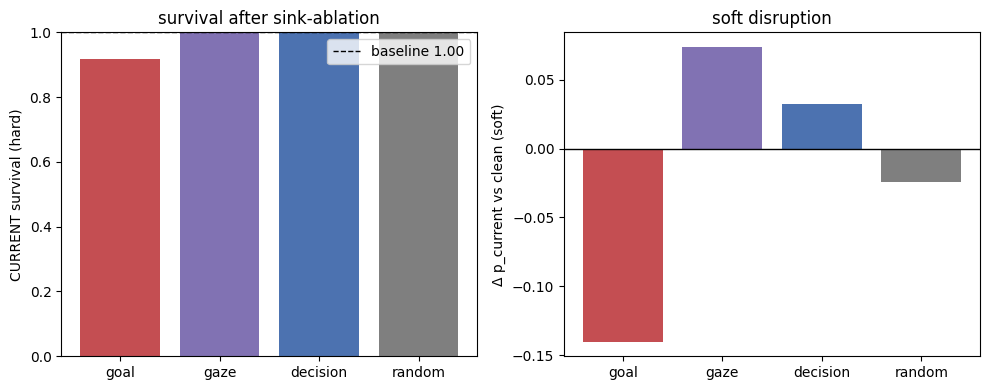

In [14]:
# ── aggregate §4 — survival drop by ablated head set ──────────────────────────
import pandas as pd
from rich.table import Table

df_abl = pd.read_json(CKPT_ABL, lines=True)
base_abl = df_abl[df_abl.headset == "baseline"]
iv_abl   = df_abl[df_abl.headset != "baseline"].copy()

summ = iv_abl.groupby("headset").agg(
    n=("headset", "size"),
    survives=("survives", "mean"),            # hard: CURRENT still implemented (LOWER = more disruption)
    soft_current=("current_is_argmax", "mean"),
    p_current=("p_current", "mean"),
    dp_current=("dp_current", "mean"),        # change in p_current vs clean (more negative = disrupted)
    rank_current=("rank_current", "mean"),
).reindex(HEADSET_NAMES)

base_surv = base_abl.survives.mean()
t = Table(title=f"§4 sink-ablation — CURRENT survival  (N={df_abl.example_id.nunique()}, "
                f"baseline survives={base_surv:.2f})")
for c, j in [("head-set","left"),("n","right"),("survives↓","right"),("soft-cur","right"),
             ("p_cur","right"),("Δp_cur","right"),("rank_cur","right")]:
    t.add_column(c, justify=j)
for hs in HEADSET_NAMES:
    s = summ.loc[hs]; style = "bold" if hs != "random" else "grey58"
    t.add_row(hs, str(int(s.n)), f"{s.survives:.2f}", f"{s.soft_current:.2f}",
              f"{s.p_current:.2f}", f"{s.dp_current:+.2f}", f"{s.rank_current:.2f}", style=style)
rich_print(t)
rich_print("[grey58]lower survival / more-negative Δp_cur than random = that head set carries the "
           "current intent.[/grey58]")

import matplotlib.pyplot as plt
COLORS = {"goal": "#c44e52", "gaze": "#8172b3", "decision": "#4c72b0", "random": "#7f7f7f"}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x = np.arange(len(HEADSET_NAMES))
ax[0].bar(x, summ.survives, color=[COLORS[h] for h in HEADSET_NAMES])
ax[0].axhline(base_surv, ls="--", c="k", lw=1, label=f"baseline {base_surv:.2f}")
ax[0].set_xticks(x); ax[0].set_xticklabels(HEADSET_NAMES); ax[0].set_ylim(0, 1)
ax[0].set_ylabel("CURRENT survival (hard)"); ax[0].set_title("survival after sink-ablation"); ax[0].legend()
ax[1].bar(x, summ.dp_current, color=[COLORS[h] for h in HEADSET_NAMES])
ax[1].set_xticks(x); ax[1].set_xticklabels(HEADSET_NAMES)
ax[1].axhline(0, c="k", lw=1); ax[1].set_ylabel("Δ p_current vs clean (soft)")
ax[1].set_title("soft disruption")
plt.tight_layout()
FIG_ABL = os.path.join(os.path.dirname(CKPT_ABL), f"{RUN_TAG_ABL}.png")
plt.savefig(FIG_ABL, dpi=110, bbox_inches="tight"); print("saved", FIG_ABL); plt.show()

     §4 hard-verdict      
distribution (fraction per
        arm, N=12)        
┏━━━━━━━━━━┳━━━━━━┳━━━━━━┓
┃ arm      ┃  YES ┃   NO ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━┩
│ baseline │ 1.00 │ 0.00 │
│ goal     │ 0.92 │ 0.08 │
│ gaze     │ 1.00 │ 0.00 │
│ decision │ 1.00 │ 0.00 │
│ random   │ 1.00 │ 0.00 │
└──────────┴──────┴──────┘

saved /disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/ablation_sink_n12_verdicts.png


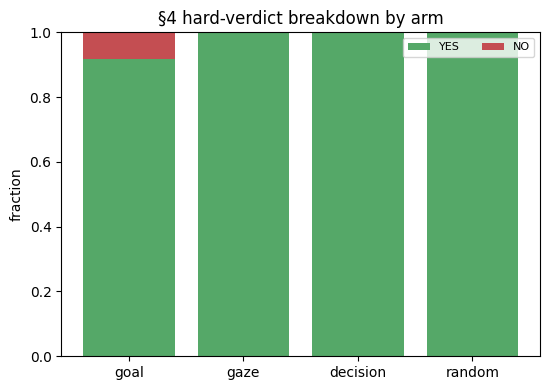

In [15]:
# ── §4 hard-verdict distribution — WHY it (doesn't) survive: NO=wrong check / NO_INFO=too generic / MALFORMED=degenerate
from rich.table import Table
import matplotlib.pyplot as plt

VERD = ["YES", "NO", "NO_INFO", "MALFORMED", "UNPARSED"]
VCOL = {"YES": "#55a868", "NO": "#c44e52", "NO_INFO": "#ccb974", "MALFORMED": "#937860", "UNPARSED": "#333333"}

if "hard_verdict" not in df_abl.columns:
    rich_print("[grey58](§4: no hard_verdict column — this checkpoint predates the single-condition "
               "oracle; delete it and re-run the run-cell to populate.)[/grey58]")
else:
    vd = (df_abl.groupby("headset")["hard_verdict"].value_counts(normalize=True)
            .unstack(fill_value=0).reindex(index=["baseline"] + HEADSET_NAMES, columns=VERD, fill_value=0))
    show_v = [v for v in VERD if vd[v].sum() > 0]                      # hide all-zero verdict columns

    tv = Table(title="§4 hard-verdict distribution (fraction per arm, N={})".format(df_abl.example_id.nunique()))
    tv.add_column("arm", justify="left")
    for v in show_v:
        tv.add_column(v, justify="right")
    for hs in ["baseline"] + HEADSET_NAMES:
        st = "grey58" if hs in ("baseline", "random") else "bold"
        tv.add_row(hs, *[f"{vd.loc[hs, v]:.2f}" for v in show_v], style=st)
    rich_print(tv)

    # stacked-bar over the intervened arms
    arms = vd.reindex(HEADSET_NAMES)
    fig, axv = plt.subplots(figsize=(5.6, 4))
    bottom = np.zeros(len(HEADSET_NAMES))
    for v in show_v:
        axv.bar(HEADSET_NAMES, arms[v], bottom=bottom, label=v, color=VCOL[v])
        bottom += arms[v].values
    axv.set_ylim(0, 1); axv.set_ylabel("fraction"); axv.legend(fontsize=8, ncol=2)
    axv.set_title("§4 hard-verdict breakdown by arm")
    plt.tight_layout()
    FIG_V = os.path.join(os.path.dirname(CKPT_ABL), f"{RUN_TAG_ABL}_verdicts.png")
    plt.savefig(FIG_V, dpi=110, bbox_inches="tight"); print("saved", FIG_V); plt.show()

## 8. Scaled §5 — isolation: only the selected set may see the CURRENT span

The opposite test. Blind the **complement** (all heads in layers `>= FROM_LAYER_IDX` except the
selected set) to the CURRENT condition's spec-text span — so only the selected set (+ untouched early
layers) can route *what is being implemented*. If CURRENT still survives, that set **suffices** to
carry the current intent to the pivot. Reuses `locate_condition_spans` / `condition_block_positions`
/ `complement_heads` from §5.

In [16]:
# ── config + per-example runner (blind complement) ────────────────────────────
N_SAMPLES_ISO = 12
K_RANGE_ISO   = (4, 6)
MAX_NEW_ISO   = 48               # generate past the next var, then rule-cut
BASE_SEED_ISO = 3000
FROM_LAYER_ISO = FROM_LAYER_IDX          # reuse §5's knob (layers >= this get blinded)
BLOCK_WHICH_ISO = "full"                 # "full" spec span | "id" discriminative substrings
RUN_TAG_ISO   = f"isolation_blind_L{FROM_LAYER_ISO}_{BLOCK_WHICH_ISO}_n{N_SAMPLES_ISO}"
CKPT_ISO = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "middle",
                        MODEL_NAME.split("/")[-1], f"{RUN_TAG_ISO}.jsonl")
os.makedirs(os.path.dirname(CKPT_ISO), exist_ok=True)
print(f"checkpoint -> {CKPT_ISO}")

ISO_SETS = {"goal": goal_heads, "gaze": gaze_heads, "decision": decision_heads, "random": RAND_ABL}


def run_one_isolation(i):
    rng = random.Random(BASE_SEED_ISO + i)
    K = rng.randint(*K_RANGE_ISO)
    current = rng.randint(1, K - 2)
    ex    = build_dissociation_prompt(mt, random.Random(7 * BASE_SEED_ISO + i),
                                      current_slot=current, n_conditions=K)
    spans = locate_condition_spans(mt, ex)
    block_pos = condition_block_positions(spans, current, BLOCK_WHICH_ISO)
    block_pos = (
        list(range(block_pos[0] - 1, len(ex["prompt_ids"]))) if block_pos else []
    )  #! block from a few tokens before the span to the end of the prompt
    if not block_pos:
        return None                                             # current span not located -> skip
    refs = get_condition_references(mt, ex)
    q_start = ex["pivot_pos"]
    blocked_txt = mt.tokenizer.decode([ex["prompt_ids"][p] for p in block_pos])

    ll_clean = score_condition_lls(mt, ex, refs)                # all heads see everything
    m_clean  = soft_metrics_current(ll_clean, current)
    common = dict(example_id=i, K=K, current=current,
                  current_pred=ex["spec"].predicate_ids[current],
                  current_text=ex["spec"].spec_texts[current],
                  spec_texts=list(ex["spec"].spec_texts), var_names=list(ex["var_names"]),
                  dissoc_prompt=ex["dissoc_prompt"], pivot_pos=ex["pivot_pos"],
                  ref_rhs=[r["rhs"] for r in refs], oracle_system=HARD_SYS,
                  blocked_txt=blocked_txt, block_pos=[int(p) for p in block_pos],
                  from_layer=FROM_LAYER_ISO, block_which=BLOCK_WHICH_ISO,
                  p_current_clean=m_clean["p_current"])

    def _rec(headset, m, comp):
        raw  = generate_blocking_span(mt, ex["prompt_ids"], comp, block_pos, q_start,
                                      MAX_NEW_ISO, stop_suffix=None)
        stub = isolate_current_span(raw, ex, current)          # rule-based cut to CURRENT's code
        oracle = judge_current(stub, ex["spec"].spec_texts[current])   # lenient single-condition hard eval
        survives = oracle["verdict"] == "YES"
        return dict(**common, headset=headset, n_blinded=len(comp),
                    p_current=m["p_current"], dp_current=m["p_current"] - m_clean["p_current"],
                    current_is_argmax=m["current_is_argmax"], rank_current=m["rank_current"],
                    soft_p=[float(x) for x in m["p"]],
                    gen_stub=stub, gen_full=raw,
                    hard_verdict=oracle["verdict"], oracle=oracle, survives=survives)

    recs = [_rec("baseline", m_clean, [])]                      # nobody blinded -> should implement CURRENT
    for hs in HEADSET_NAMES:
        comp = complement_heads(ISO_SETS[hs], FROM_LAYER_ISO)   # blind everyone else to the span
        ll   = score_condition_lls(mt, ex, refs,
                                   forward_fn=lambda inp, qp, c=comp: forward_blocking_span(mt, inp, c, block_pos, qp))
        recs.append(_rec(hs, soft_metrics_current(ll, current), comp))
    return recs

checkpoint -> /disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/isolation_blind_L20_full_n12.jsonl


In [17]:
# ── run (checkpointed / resumable) ──
done = set()
if os.path.exists(CKPT_ISO):
    with open(CKPT_ISO) as f:
        for line in f:
            done.add(json.loads(line)["example_id"])
logger.info(f"resuming: {len(done)} in {os.path.basename(CKPT_ISO)}")

run_results = []
n_skipped = 0
for i in range(N_SAMPLES_ISO):
    if i in done:
        continue
    recs = run_one_isolation(i)
    if recs is None:
        n_skipped += 1
        logger.info(f"[{i+1:>3}/{N_SAMPLES_ISO}] span not located -> skipped")
        continue
    with open(CKPT_ISO, "a") as f:
        for r in recs:
            f.write(json.dumps(r) + "\n")
    surv = {r["headset"]: ("Y" if r["survives"] else ".") for r in recs}
    run_results.extend(recs)
    logger.info(f"[{i+1:>3}/{N_SAMPLES_ISO}] K={recs[0]['K']} cur={recs[0]['current']} :: {surv}")
print(f"done. ({n_skipped} skipped)")

2026-07-24 15:48:07 __main__ INFO     resuming: 0 in isolation_blind_L20_full_n12.jsonl
2026-07-24 15:48:10 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:48:22 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:48:30 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:48:39 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:48:39 __main__ INFO     [  1/12] K=6 cur=2 :: {'baseline': 'Y', 'goal': 'Y', 'gaze': '.', 'decision': '.', 'random': '.'}
2026-07-24 15:48:42 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:48:49 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-07-24 15:48:55 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-0

  §5 isolation — CURRENT survival with only <set> seeing the span   
                       (N=12, baseline=1.00)                        
┏━━━━━━━━━━┳━━━━┳━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━┳━━━━━━━━┳━━━━━━━━━━┓
┃ only-set ┃  n ┃ survives↑ ┃ soft-cur ┃ p_cur ┃ Δp_cur ┃ #blinded ┃
┡━━━━━━━━━━╇━━━━╇━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━╇━━━━━━━━╇━━━━━━━━━━┩
│ goal     │ 12 │      0.92 │     0.67 │  0.36 │  -0.05 │     1638 │
│ gaze     │ 12 │      0.08 │     0.00 │  0.12 │  -0.29 │     1644 │
│ decision │ 12 │      0.17 │     0.25 │  0.17 │  -0.23 │     1589 │
│ random   │ 12 │      0.08 │     0.17 │  0.16 │  -0.25 │     1638 │
└──────────┴────┴───────────┴──────────┴───────┴────────┴──────────┘

higher survival than random = that set alone suffices to route the current condition to the pivot.

saved /disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/isolation_blind_L20_full_n12.png


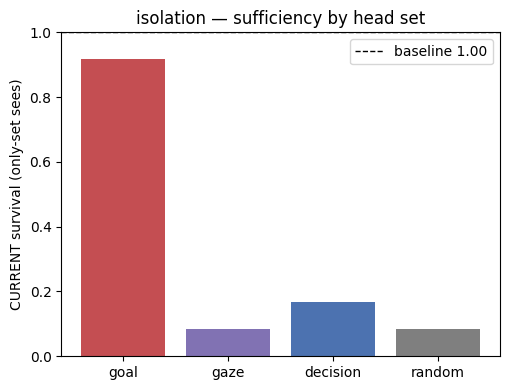

In [18]:
# ── aggregate §5 — survival when only the selected set sees CURRENT ────────────
import pandas as pd
from rich.table import Table

df_iso = pd.read_json(CKPT_ISO, lines=True)
base_iso = df_iso[df_iso.headset == "baseline"]
iv_iso   = df_iso[df_iso.headset != "baseline"].copy()

summ_i = iv_iso.groupby("headset").agg(
    n=("headset", "size"),
    survives=("survives", "mean"),            # hard: CURRENT survives with only this set seeing (HIGHER = sufficient)
    soft_current=("current_is_argmax", "mean"),
    p_current=("p_current", "mean"),
    dp_current=("dp_current", "mean"),
    n_blinded=("n_blinded", "mean"),
).reindex(HEADSET_NAMES)

base_surv_i = base_iso.survives.mean()
t = Table(title=f"§5 isolation — CURRENT survival with only <set> seeing the span  "
                f"(N={df_iso.example_id.nunique()}, baseline={base_surv_i:.2f})")
for c, j in [("only-set","left"),("n","right"),("survives↑","right"),("soft-cur","right"),
             ("p_cur","right"),("Δp_cur","right"),("#blinded","right")]:
    t.add_column(c, justify=j)
for hs in HEADSET_NAMES:
    s = summ_i.loc[hs]; style = "bold" if hs != "random" else "grey58"
    t.add_row(hs, str(int(s.n)), f"{s.survives:.2f}", f"{s.soft_current:.2f}",
              f"{s.p_current:.2f}", f"{s.dp_current:+.2f}", f"{s.n_blinded:.0f}", style=style)
rich_print(t)
rich_print("[grey58]higher survival than random = that set alone suffices to route the current "
           "condition to the pivot.[/grey58]")

import matplotlib.pyplot as plt
COLORS = {"goal": "#c44e52", "gaze": "#8172b3", "decision": "#4c72b0", "random": "#7f7f7f"}
fig, ax = plt.subplots(figsize=(5.2, 4))
x = np.arange(len(HEADSET_NAMES))
ax.bar(x, summ_i.survives, color=[COLORS[h] for h in HEADSET_NAMES])
ax.axhline(base_surv_i, ls="--", c="k", lw=1, label=f"baseline {base_surv_i:.2f}")
ax.set_xticks(x); ax.set_xticklabels(HEADSET_NAMES); ax.set_ylim(0, 1)
ax.set_ylabel("CURRENT survival (only-set sees)")
ax.set_title("isolation — sufficiency by head set"); ax.legend()
plt.tight_layout()
FIG_ISO = os.path.join(os.path.dirname(CKPT_ISO), f"{RUN_TAG_ISO}.png")
plt.savefig(FIG_ISO, dpi=110, bbox_inches="tight"); print("saved", FIG_ISO); plt.show()

§5 hard-verdict distribution (fraction per arm, 
                     N=12)                      
┏━━━━━━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━┓
┃ arm      ┃  YES ┃   NO ┃ NO_INFO ┃ MALFORMED ┃
┡━━━━━━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━┩
│ baseline │ 1.00 │ 0.00 │    0.00 │      0.00 │
│ goal     │ 0.92 │ 0.00 │    0.00 │      0.08 │
│ gaze     │ 0.08 │ 0.75 │    0.00 │      0.17 │
│ decision │ 0.17 │ 0.83 │    0.00 │      0.00 │
│ random   │ 0.08 │ 0.75 │    0.08 │      0.08 │
└──────────┴──────┴──────┴─────────┴───────────┘

saved /disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/isolation_blind_L20_full_n12_verdicts.png


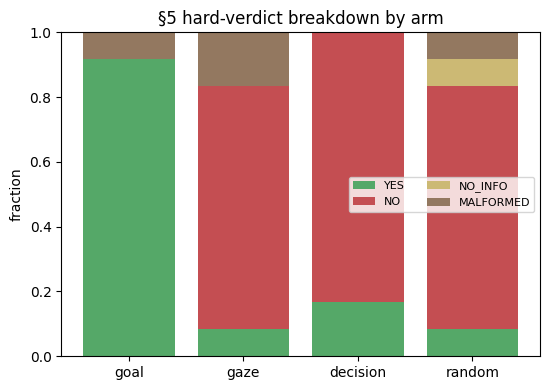

In [19]:
# ── §5 hard-verdict distribution — WHY it (doesn't) survive: NO=wrong check / NO_INFO=too generic / MALFORMED=degenerate
from rich.table import Table
import matplotlib.pyplot as plt

VERD = ["YES", "NO", "NO_INFO", "MALFORMED", "UNPARSED"]
VCOL = {"YES": "#55a868", "NO": "#c44e52", "NO_INFO": "#ccb974", "MALFORMED": "#937860", "UNPARSED": "#333333"}

if "hard_verdict" not in df_iso.columns:
    rich_print("[grey58](§5: no hard_verdict column — this checkpoint predates the single-condition "
               "oracle; delete it and re-run the run-cell to populate.)[/grey58]")
else:
    vd = (df_iso.groupby("headset")["hard_verdict"].value_counts(normalize=True)
            .unstack(fill_value=0).reindex(index=["baseline"] + HEADSET_NAMES, columns=VERD, fill_value=0))
    show_v = [v for v in VERD if vd[v].sum() > 0]                      # hide all-zero verdict columns

    tv = Table(title="§5 hard-verdict distribution (fraction per arm, N={})".format(df_iso.example_id.nunique()))
    tv.add_column("arm", justify="left")
    for v in show_v:
        tv.add_column(v, justify="right")
    for hs in ["baseline"] + HEADSET_NAMES:
        st = "grey58" if hs in ("baseline", "random") else "bold"
        tv.add_row(hs, *[f"{vd.loc[hs, v]:.2f}" for v in show_v], style=st)
    rich_print(tv)

    # stacked-bar over the intervened arms
    arms = vd.reindex(HEADSET_NAMES)
    fig, axv = plt.subplots(figsize=(5.6, 4))
    bottom = np.zeros(len(HEADSET_NAMES))
    for v in show_v:
        axv.bar(HEADSET_NAMES, arms[v], bottom=bottom, label=v, color=VCOL[v])
        bottom += arms[v].values
    axv.set_ylim(0, 1); axv.set_ylabel("fraction"); axv.legend(fontsize=8, ncol=2)
    axv.set_title("§5 hard-verdict breakdown by arm")
    plt.tight_layout()
    FIG_V = os.path.join(os.path.dirname(CKPT_ISO), f"{RUN_TAG_ISO}_verdicts.png")
    plt.savefig(FIG_V, dpi=110, bbox_inches="tight"); print("saved", FIG_V); plt.show()

In [20]:
with open("/disk/u/arnab/Codes/Projects/goals/results/middle/Qwen2.5-Coder-32B-Instruct/isolation_blind_L20_full_n12.jsonl") as f:
    run_results = [json.loads(line) for line in f]

filtered = [
    rec for rec in run_results if rec["headset"] == "goal" and rec["survives"] == False
]
len(filtered)

1

In [22]:
ORACLE_SYS_2 = """You are grading a short snippet of Python CODE against ONE natural-language CONDITION. The code is the right-hand side of an assignment that a model produced while (under a mechanistic intervention) trying to implement that condition on its input. Because of the intervention the code is often NOISY: it may have minor bugs, use a wrong constant / threshold / operator, be incomplete or cut off, contain half-written or repeated fragments, or wander. Look PAST that surface noise and grade only the SUBSTANCE.

The question: does the CODE do something genuinely relevant to the CONDITION — a genuine attempt at, or a non-trivial step toward, implementing that condition? Even a small correct fragment of the right idea is a SUCCESS, so grade as leniently as possible.

The following do NOT count against the code (still YES):
  - Wrong specifics: a wrong constant, threshold, bound, modulus, operator, or comparison direction. If the condition is "average temperature > 30" and the code computes the average / compares the relevant quantity, that is YES even if the number or operator is off or missing.
  - Wrong implementation nuance: a different but plausible mechanism for the same idea (e.g. the condition wants a palindrome check and the code reverses a string and compares it, even with a buggy method call) -> YES.
  - Incomplete or cut-off code, or broken / repetitive fragments, AS LONG AS what IS there is relevant to the condition.
  - Partial coverage: implementing just one relevant ingredient of a multi-part condition counts.

Answer with exactly one token:
  YES        - the code contains SOME operation, quantity, or sub-step genuinely relevant to the condition, however partial, buggy, or incomplete.
  NO         - the code is coherent and about a specific thing, but that thing is UNRELATED to the condition (it implements a different check).
  NO_INFO    - the code is coherent but too generic or trivial to indicate the condition (e.g. just `n`, `True`, or a bare `n > 0` with no tie to the condition\'s concept).
  MALFORMED  - the code is contentless: empty, pure punctuation / garbage, or repetition carrying no relevant meaning.

Grade on meaning, not on shared keywords. Output only YES, NO, NO_INFO, or MALFORMED. 
Put your one word answer inside <verdict></verdict> tags to make it easy to parse."""

condition_text = "n is smaller than the number obtained by reversing its digits"
code_stub = "int(str(n)[::-1]) < n"
# code_stub = "n < "

# condition_text = "n is a prime number"
# code_stub = "all(n % i != 0 for i in"

prompt = f"Condition: {condition_text}\nCode stub: {code_stub}\nAnswer:"

ask_claude(
    prompt=prompt,
    system_prompt=ORACLE_SYS_2,
    temperature=0.0,
    max_tokens=256,
    use_cache=False,
    model_name=ORACLE_MODEL,
)

2026-07-24 15:55:59 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


'The condition says n < reverse(n), but the code checks reverse(n) < n (the opposite direction). However, the code does compute the reversal and compare it to n, which is genuinely relevant to the condition (just with the wrong comparison direction).\n\n<verdict>YES</verdict>'

In [ ]:
judge_current(
    code_stub=code_stub,
    condition_text=condition_text,
    use_cache=False
)

2026-07-24 15:56:02 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


{'verdict': 'YES',
 'condition': 'n is smaller than the number obtained by reversing its digits',
 'code_stub': 'int(str(n)[::-1]) < n',
 'system': 'You are grading a short snippet of Python CODE against ONE natural-language CONDITION. The code is the right-hand side of an assignment that a model produced while (under a mechanistic intervention) trying to implement that condition on its input. Because of the intervention the code is often NOISY: it may have minor bugs, use a wrong constant / threshold / operator, be incomplete or cut off, contain half-written or repeated fragments, or wander. Look PAST that surface noise and grade only the SUBSTANCE.\n\nThe question: does the CODE do something genuinely relevant to the CONDITION — a genuine attempt at, or a non-trivial step toward, implementing that condition? Even a small correct fragment of the right idea is a SUCCESS, so grade as leniently as possible.\n\nThe following do NOT count against the code (still YES):\n  - Wrong specifics:

: 